# Universidad Nacional de Colombia  
## Sede Bogotá  
### Facultad de Ingeniería
### Departamento de Ingeniería de Sistemas e Industrial

---

## **Inteligencia Artificial y Mini-robots**

**Título del Taller:**  
*Introducción a las redes neuronales*

**Autor:**  
*Juan Jeronimo Gómez Rubiano*  

**Periodo:**  
*2025-2*

**Fecha de entrega:**  
*Septiembre 23/2025*

---

*El source code junto a este documento es encuentran disponible en el siguiente repositorio público de github: https://github.com/jujgomezru/ia-minirobots*

## Ejercicio 1

### Con base en el programa Clase_NNA3, desarrolle dos redes neuronales con 2 capas oculta, una que aprenda a reconocer una compuerta NAND y la otra aprenda a reconocer una compuerta XOR.

In [8]:
import numpy as np

Primero, vamos a definir las funciones matemáticas básicas que componen a una red neuronal. En este caso, vamos a usar la función sigmoide como la función de activación. También usamos las funciones de propagación, calculo de error, y retropropagación, necesarias para la función de aprendizaje de la red neuronal.

In [11]:
# Funciones de activación y derivada
def sig(s):
    return 1/(1+np.exp(-s))

def dSig(s):
    sig_s = sig(s)
    return np.diagflat(sig_s * (1 - sig_s))

# Función de propagación hacia adelante
def propaga(Xo, W1, b1, W2, b2):
    Z1 = np.dot(W1, Xo) + b1
    A1 = sig(Z1)              
    Z2 = np.dot(W2, A1) + b2
    A2 = sig(Z2)              
    return A2, Z2, A1, Z1

# Función de error
def error(A2, Yd):
    return Yd - A2

# Backpropagation
def backpropagation(X, Yd, A2, Z2, A1, Z1, W2):
    delta2 = np.dot(dSig(Z2), error(A2, Yd))
    dEdW2 = -np.dot(delta2, A1.T)
    dEdb2 = -delta2
    
    delta1 = np.dot(np.dot(dSig(Z1), W2.T), delta2)
    dEdW1 = -np.dot(delta1, X.T)
    dEdb1 = -delta1
    
    return dEdW2, dEdb2, dEdW1, dEdb1

Una vez definimos las funciones básicas de una red neuronal, procedemos a realizar el entrenamiento para las compuertas NAND y XOR. Para esto aprovechamos que conocemos la tabla de verdad de ambas compuertas lógicas, y las aplicamos como las entradas y predicciones esperadas, para que durante el entrenamiento, se ajusten los pesos necesarios para obtener la red neuronal final.

In [16]:
# Función para mostrar los pesos de forma detallada
def analizar_pesos(W1, b1, W2, b2, nombre_compuerta):
    print(f"\n=== ANÁLISIS DE PESOS - {nombre_compuerta} ===")
    
    print("\n🔹 CAPA OCULTA (2 neuronas):")
    for i in range(2):
        print(f"   Neurona Oculta {i+1}:")
        print(f"   Pesos de entrada: [{W1[i, 0]:.4f}, {W1[i, 1]:.4f}]")
        print(f"   Sesgo (bias): {b1[i, 0]:.4f}")
    
    print("\n🔹 CAPA DE SALIDA (1 neurona):")
    print(f"   Pesos desde capa oculta: [{W2[0, 0]:.4f}, {W2[0, 1]:.4f}]")
    print(f"   Sesgo (bias): {b2[0, 0]:.4f}")
    
    # Probar todas las combinaciones
    print(f"\n🔍 RESULTADOS FINALES:")
    entradas = [np.array([[0], [0]]), np.array([[0], [1]]), 
                np.array([[1], [0]]), np.array([[1], [1]])]
    
    for X in entradas:
        A2, Z2, A1, Z1 = propaga(X, W1, b1, W2, b2)
        activacion_oculta = [f"{a:.4f}" for a in A1.flatten()]
        decision = "1" if A2[0,0] > 0.5 else "0"
        print(f"   Entrada {X.flatten()} -> Oculta: {activacion_oculta} -> Salida: {A2[0,0]:.4f} -> Decisión: {decision}")

# Función de entrenamiento única que retorna pesos
def entrenar_compuerta(nombre, X_datos, Yd_datos, epochs):
    print(f"\n=== ENTRENAMIENTO COMPUERTA {nombre} ===")
    
    # Inicialización de pesos y sesgos
    np.random.seed(42)
    W1 = np.random.randn(2, 2) * 0.1
    b1 = np.random.randn(2, 1) * 0.1
    W2 = np.random.randn(1, 2) * 0.1
    b2 = np.random.randn(1, 1) * 0.1

    eta = 0.5

    # Entrenamiento
    for i in range(epochs):
        for X, Yd in zip(X_datos, Yd_datos):
            A2, Z2, A1, Z1 = propaga(X, W1, b1, W2, b2)
            dEdW2, dEdb2, dEdW1, dEdb1 = backpropagation(X, Yd, A2, Z2, A1, Z1, W2)
            
            W2 -= eta * dEdW2
            b2 -= eta * dEdb2
            W1 -= eta * dEdW1
            b1 -= eta * dEdb1

    # Verificación final
    print(f"Resultados {nombre}:")
    for X in X_datos:
        A2, _, _, _ = propaga(X, W1, b1, W2, b2)
        print(f"  Entrada: {X.flatten()} -> Salida: {A2[0,0]:.4f}")
    
    return W1, b1, W2, b2

# Datos de entrenamiento
X_nand = [np.array([[0], [0]]), np.array([[0], [1]]), 
          np.array([[1], [0]]), np.array([[1], [1]])]
Yd_nand = [np.array([[1]]), np.array([[1]]), 
           np.array([[1]]), np.array([[0]])]

X_xor = [np.array([[0], [0]]), np.array([[0], [1]]), 
         np.array([[1], [0]]), np.array([[1], [1]])]
Yd_xor = [np.array([[0]]), np.array([[1]]), 
          np.array([[1]]), np.array([[0]])]

# ENTRENAMIENTO Y ANÁLISIS
# Entrenar NAND y analizar pesos
W1_nand, b1_nand, W2_nand, b2_nand = entrenar_compuerta("NAND", X_nand, Yd_nand, 10000)
analizar_pesos(W1_nand, b1_nand, W2_nand, b2_nand, "NAND")

# Entrenar XOR y analizar pesos
W1_xor, b1_xor, W2_xor, b2_xor = entrenar_compuerta("XOR", X_xor, Yd_xor, 20000)
analizar_pesos(W1_xor, b1_xor, W2_xor, b2_xor, "XOR")


=== ENTRENAMIENTO COMPUERTA NAND ===
Resultados NAND:
  Entrada: [0 0] -> Salida: 0.9996
  Entrada: [0 1] -> Salida: 0.9901
  Entrada: [1 0] -> Salida: 0.9901
  Entrada: [1 1] -> Salida: 0.0177

=== ANÁLISIS DE PESOS - NAND ===

🔹 CAPA OCULTA (2 neuronas):
   Neurona Oculta 1:
   Pesos de entrada: [-3.7987, -3.8486]
   Sesgo (bias): 5.1738
   Neurona Oculta 2:
   Pesos de entrada: [-2.7656, -2.7045]
   Sesgo (bias): 3.3798

🔹 CAPA DE SALIDA (1 neurona):
   Pesos desde capa oculta: [8.0577, 5.2158]
   Sesgo (bias): -5.2147

🔍 RESULTADOS FINALES:
   Entrada [0 0] -> Oculta: ['0.9944', '0.9671'] -> Salida: 0.9996 -> Decisión: 1
   Entrada [0 1] -> Oculta: ['0.7900', '0.6627'] -> Salida: 0.9901 -> Decisión: 1
   Entrada [1 0] -> Oculta: ['0.7982', '0.6489'] -> Salida: 0.9901 -> Decisión: 1
   Entrada [1 1] -> Oculta: ['0.0777', '0.1100'] -> Salida: 0.0177 -> Decisión: 0

=== ENTRENAMIENTO COMPUERTA XOR ===
Resultados XOR:
  Entrada: [0 0] -> Salida: 0.0118
  Entrada: [0 1] -> Salida: 0.98

En los resultados, podemos observar que no solo las redes neuronales obtenidas son muy efectivas para la activación correspondiente a las puertas lógicas, sino que podemos observar los pesos que usan las 3 neuronas (2 ocultas y la neurona de salida) para construir el modelo de activación de cada una de las dos compuertas lógicas construidas. Llama la atención que los resultados de la neurona de salida no son 0 y 1, pero son lo suficientemente cercanos para facilitar la decisión de activación por parte de la función. También llama la atención que la compuerta NAND es simétrica, lo que define que se requiera la activación de ambas neuronas para una respuesta negativa, y en cambio, la compuerta XOR es asimétrica, lo que refleja que la red neuronal necesita caminos aparte para asegurar la inactivación en la entrada [0 0] o por la entrada [1 1] 

## Ejercicio 2

### Con base en la librería tensorflow, descargue el data set fashion MNIST. Haga una clasificación de prendas de vestir. Explique cada una de las funciones y las principales instrucciones, saque conclusiones.

In [13]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten
from tensorflow.keras.utils import to_categorical
import numpy as np
import matplotlib.pyplot as plt

Primero, buscamos la librería tensorflow online, y buscamos las instrucciones para descargar el dataset de prendas de vestir **MNIST**. Una vez obtenemos el dataset, vamos a realizar un análisis exploratorio sencillo:

Forma del conjunto de entrenamiento: (60000, 28, 28)
Forma de las etiquetas de entrenamiento: (60000,)
Valores únicos en las etiquetas: [0 1 2 3 4 5 6 7 8 9]


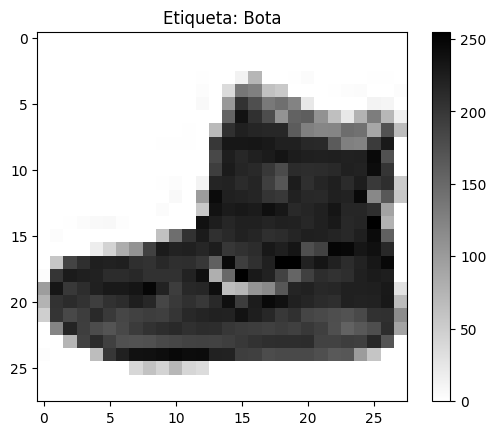

/home/jujgomezru/.local/lib/python3.13/site-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
2025-09-23 22:40:20.094742: W external/local_xla/xla/tsl/framework/cpu_allocator_impl.cc:84] Allocation of 150528000 exceeds 10% of free system memory.


Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 10ms/step - accuracy: 0.8212 - loss: 0.5145 - val_accuracy: 0.8550 - val_loss: 0.4045
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8619 - loss: 0.3857 - val_accuracy: 0.8577 - val_loss: 0.3943
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.8742 - loss: 0.3470 - val_accuracy: 0.8676 - val_loss: 0.3582
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8830 - loss: 0.3189 - val_accuracy: 0.8773 - val_loss: 0.3418
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8882 - loss: 0.2999 - val_accuracy: 0.8704 - val_loss: 0.3654
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.8954 - loss: 0.2844 - val_accuracy: 0.8801 - val_loss: 0.3387
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 8ms/step - accuracy: 0.9020 - loss: 0.2689 - val_accuracy: 0.8824 - val_loss: 0.3325
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 7ms/step - accuracy: 0.9025 - loss: 0.26

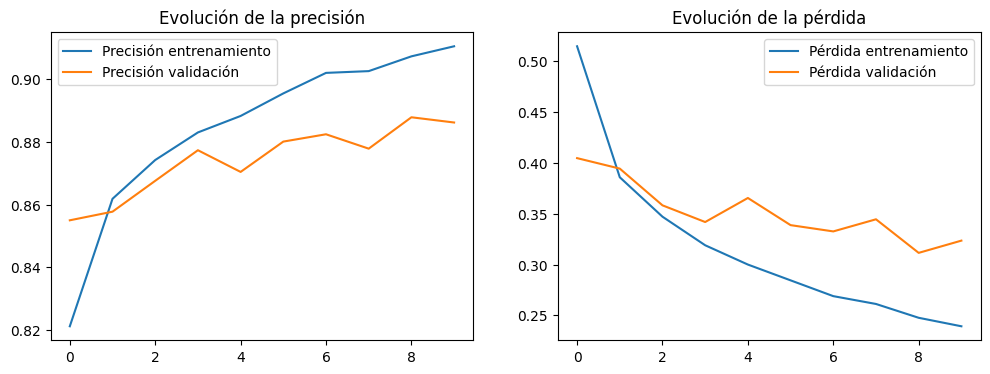

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step

Predicción para primera imagen de prueba: 9
Etiqueta real: 9 (Bota)


In [14]:
# 1. Cargar el dataset Fashion MNIST
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

"""
Explicación:
- tf.keras.datasets.fashion_mnist.load_data(): Descarga y carga el dataset automáticamente
- Retorna dos tuplas: (imágenes de entrenamiento, etiquetas de entrenamiento) y (imágenes de prueba, etiquetas de prueba)
- x_train/x_test: Arrays de numpy con imágenes en escala de grises (0-255)
- y_train/y_test: Arrays con etiquetas numéricas (0-9)
"""

# 2. Exploración de datos
print("Forma del conjunto de entrenamiento:", x_train.shape)  # (60000, 28, 28)
print("Forma de las etiquetas de entrenamiento:", y_train.shape)  # (60000,)
print("Valores únicos en las etiquetas:", np.unique(y_train))  # [0 1 2 3 4 5 6 7 8 9]

# Nombres de las clases
class_names = ['Camiseta', 'Pantalón', 'Suéter', 'Vestido', 'Abrigo',
               'Sandalia', 'Camisa', 'Zapatilla', 'Bolso', 'Bota']

# Visualizar una imagen de ejemplo
plt.figure()
plt.imshow(x_train[0], cmap=plt.cm.binary)
plt.title(f'Etiqueta: {class_names[y_train[0]]}')
plt.colorbar()
plt.show()

"""
Explicación:
- x_train.shape muestra (60000, 28, 28): 60,000 imágenes de 28x28 píxeles
- cmap=plt.cm.binary: Muestra la imagen en escala de grises
- np.unique() verifica que tenemos 10 clases distintas
"""

# 3. Preprocesamiento de datos
# Normalizar los valores de píxeles (0-255 -> 0-1)
x_train = x_train / 255.0
x_test = x_test / 255.0

# Convertir etiquetas a formato categórico (one-hot encoding)
y_train_categorical = to_categorical(y_train, 10)
y_test_categorical = to_categorical(y_test, 10)

"""
Explicación:
- Normalizar ayuda a que la red neuronal converja más rápido
- to_categorical convierte etiquetas numéricas en vectores binarios:
  Ejemplo: 3 -> [0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
"""

# 4. Construcción del modelo
model = Sequential([
    Flatten(input_shape=(28, 28)),  # Capa para aplanar la imagen (28x28 -> 784 pixels)
    Dense(128, activation='relu'),  # Capa densa con 128 neuronas y activación ReLU
    Dense(10, activation='softmax') # Capa de salida con 10 neuronas (una por clase)
])

"""
Explicación:
- Sequential: Modelo lineal donde las capas se apilan secuencialmente
- Flatten: Convierte la matriz 2D (28x28) en un vector 1D de 784 elementos
- Dense: Capa totalmente conectada
- ReLU (Rectified Linear Unit): Función de activación que introduce no-linealidad
- Softmax: Convierte los logits en probabilidades (suma total = 1)
"""

# 5. Compilación del modelo
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

"""
Explicación:
- optimizer='adam': Algoritmo de optimización adaptativo
- loss='categorical_crossentropy': Función de pérdida para problemas multi-clase
- metrics=['accuracy']: Métrica de evaluación (precisión)
"""

# 6. Entrenamiento del modelo
history = model.fit(x_train, y_train_categorical,
                    epochs=10,
                    validation_split=0.2)

"""
Explicación:
- epochs=10: Número de pasadas completas por el dataset
- validation_split=0.2: Usa 20% de los datos de entrenamiento para validación
- history: Objeto que guarda el historial de entrenamiento
"""

# 7. Evaluación del modelo
test_loss, test_accuracy = model.evaluate(x_test, y_test_categorical)
print(f'\nPrecisión en prueba: {test_accuracy:.4f}')

# 8. Gráficas de evolución del entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Precisión entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión validación')
plt.title('Evolución de la precisión')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Pérdida entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida validación')
plt.title('Evolución de la pérdida')
plt.legend()

plt.show()

# 9. Predicciones en ejemplos nuevos
predictions = model.predict(x_test)
print(f"\nPredicción para primera imagen de prueba: {np.argmax(predictions[0])}")
print(f"Etiqueta real: {y_test[0]} ({class_names[y_test[0]]})")

Una vez descargado el dataset de fashion MNIST, construimos una red neuronal utilizando las principales funciones de tensorflow, para mostrar el flujo de trabajo típico de las redes neuronales: Carga de datos, preprocesamiento, construcción del modelo, entrenamiento y evaluación. Las funciones más relevantes de tensorflow usadas en esta librería son:

- sequential(): Contenedor lineal para apilar capas
- flatten(): Prepara datos image para capas densas
- dense(): Capa donde cada neurona se conecta con todas las anteriores
- compile(): Configura el proceso de aprendizaje
- fit(): Entrena el modelo con los datos
- evaluate(): Mide el rendimiento en datos no vistos

Con este modelo, la red neuronal consigue un porcentaje de éxito del 88.01% Esto se considera el resultado funcional final, porque, como se observa en las gráficas de aprendizaje, inicialmente va mejorando, y eventualmente converge por encima del 85%. Llama la atención que a partir de la tercera época, se observa un mayor crecimiento del éxito en el entrenamiento que en la validación, lo que sugiere que el modelo comienza a sufrir con un poco de over-fitting en las épocas finales. Igualmente se observa que la predicción es bastante buena, dado lo desafiante del problema, ya que el dataset original presenta 28 features


## Ejercicio 3

### Consiga un data set de cualquier tipo, puede ser de https://www.kaggle.com/datasets, estudie sus características (features) y su rótulo. Diseñe una red neuronal y haga ejemplos con base en los pesos aprendidos.

Primero, vamos a instalar las librerías faltantes por el momento, para poder construir la red neuronal de este ejercicio.

In [10]:
import sys
!{sys.executable} -m pip install kagglehub
!{sys.executable} -m pip install seaborn
!{sys.executable} -m pip install scikit-learn
!{sys.executable} -m pip install tensorflow


Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 623.7 kB/s eta 0:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.4/9.4 MB 9.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 308.4/308.4 kB 3.7 MB/s eta 0:00:00:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.7/35.7 MB 3.9 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
qiskit 2.0.0 requires sympy>=1.3, which is not installed.
Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 620.8/620.8 MB ? eta 0:00:000:00:010m:06m
   ━━━━━━━━━━━━━━━━━━━

Una vez listas las librerías, vamos a descargar el data set a utilizar en este ejercicio. El dataset se llama **Adult Income Prediction Dataset**. Este dataset contiene datos derivados del censo de USA de 1994, de carácter demográfico y profesional. El objetivo del dataset, es detectar parámetros y características que permiten predecir si una persona gana más de $50.000 dólares al año.  

In [2]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("mosapabdelghany/adult-income-prediction-dataset")

print("Path to dataset files:", path)

100%|████████████████████████████████████████████████████████████████████████████████| 450k/450k [00:00<00:00, 1.96MB/s]

Extracting files...
Path to dataset files: /home/jujgomezru/.cache/kagglehub/datasets/mosapabdelghany/adult-income-prediction-dataset/versions/1


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import os

2025-09-23 20:44:36.211141: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
2025-09-23 20:44:38.693558: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2025-09-23 20:44:51.385712: I external/local_xla/xla/tsl/cuda/cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Archivos en el directorio:
- adult.csv

Dataset cargado desde: /home/jujgomezru/.cache/kagglehub/datasets/mosapabdelghany/adult-income-prediction-dataset/versions/1/adult.csv

INFORMACIÓN GENERAL DEL DATASET
Dimensiones: (32561, 15) (filas, columnas)

Primeras 5 filas:
   age workclass  fnlwgt     education  education.num marital.status  \
0   90         ?   77053       HS-grad              9        Widowed   
1   82   Private  132870       HS-grad              9        Widowed   
2   66         ?  186061  Some-college             10        Widowed   
3   54   Private  140359       7th-8th              4       Divorced   
4   41   Private  264663  Some-college             10      Separated   

          occupation   relationship   race     sex  capital.gain  \
0                  ?  Not-in-family  White  Female             0   
1    Exec-managerial  Not-in-family  White  Female             0   
2                  ?      Unmarried  Black  Female             0   
3  Machine-op-inspct     

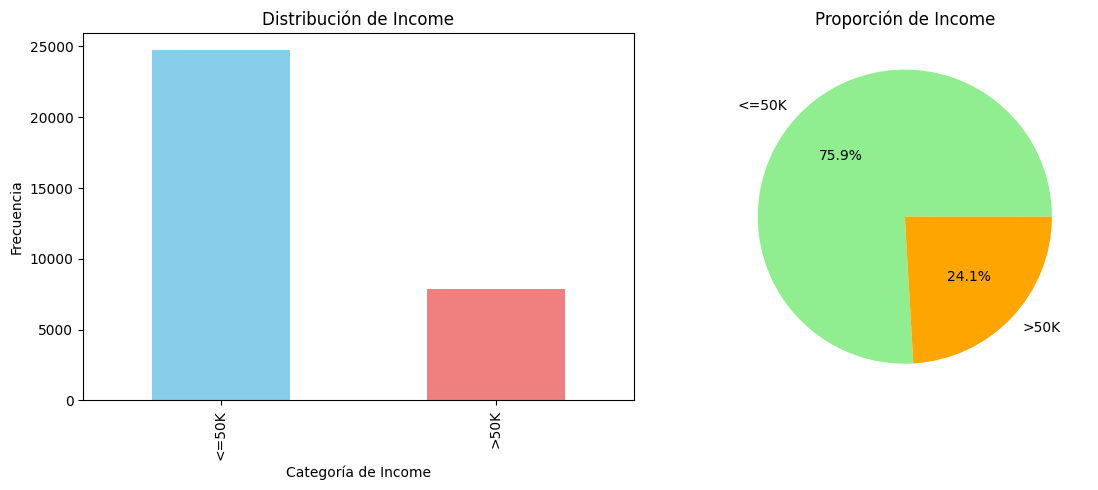


ANÁLISIS DE CARACTERÍSTICAS
Total de características: 14
Total de instancias: 32561

Características numéricas (6):
  1. age (int64)
  2. fnlwgt (int64)
  3. education.num (int64)
  4. capital.gain (int64)
  5. capital.loss (int64)
  6. hours.per.week (int64)

Características categóricas (8):
  1. workclass (9 valores únicos)
  2. education (16 valores únicos)
  3. marital.status (7 valores únicos)
  4. occupation (15 valores únicos)
  5. relationship (6 valores únicos)
  6. race (5 valores únicos)
  7. sex (2 valores únicos)
  8. native.country (42 valores únicos)

----------------------------------------
ESTADÍSTICAS DETALLADAS - VARIABLES NUMÉRICAS
----------------------------------------


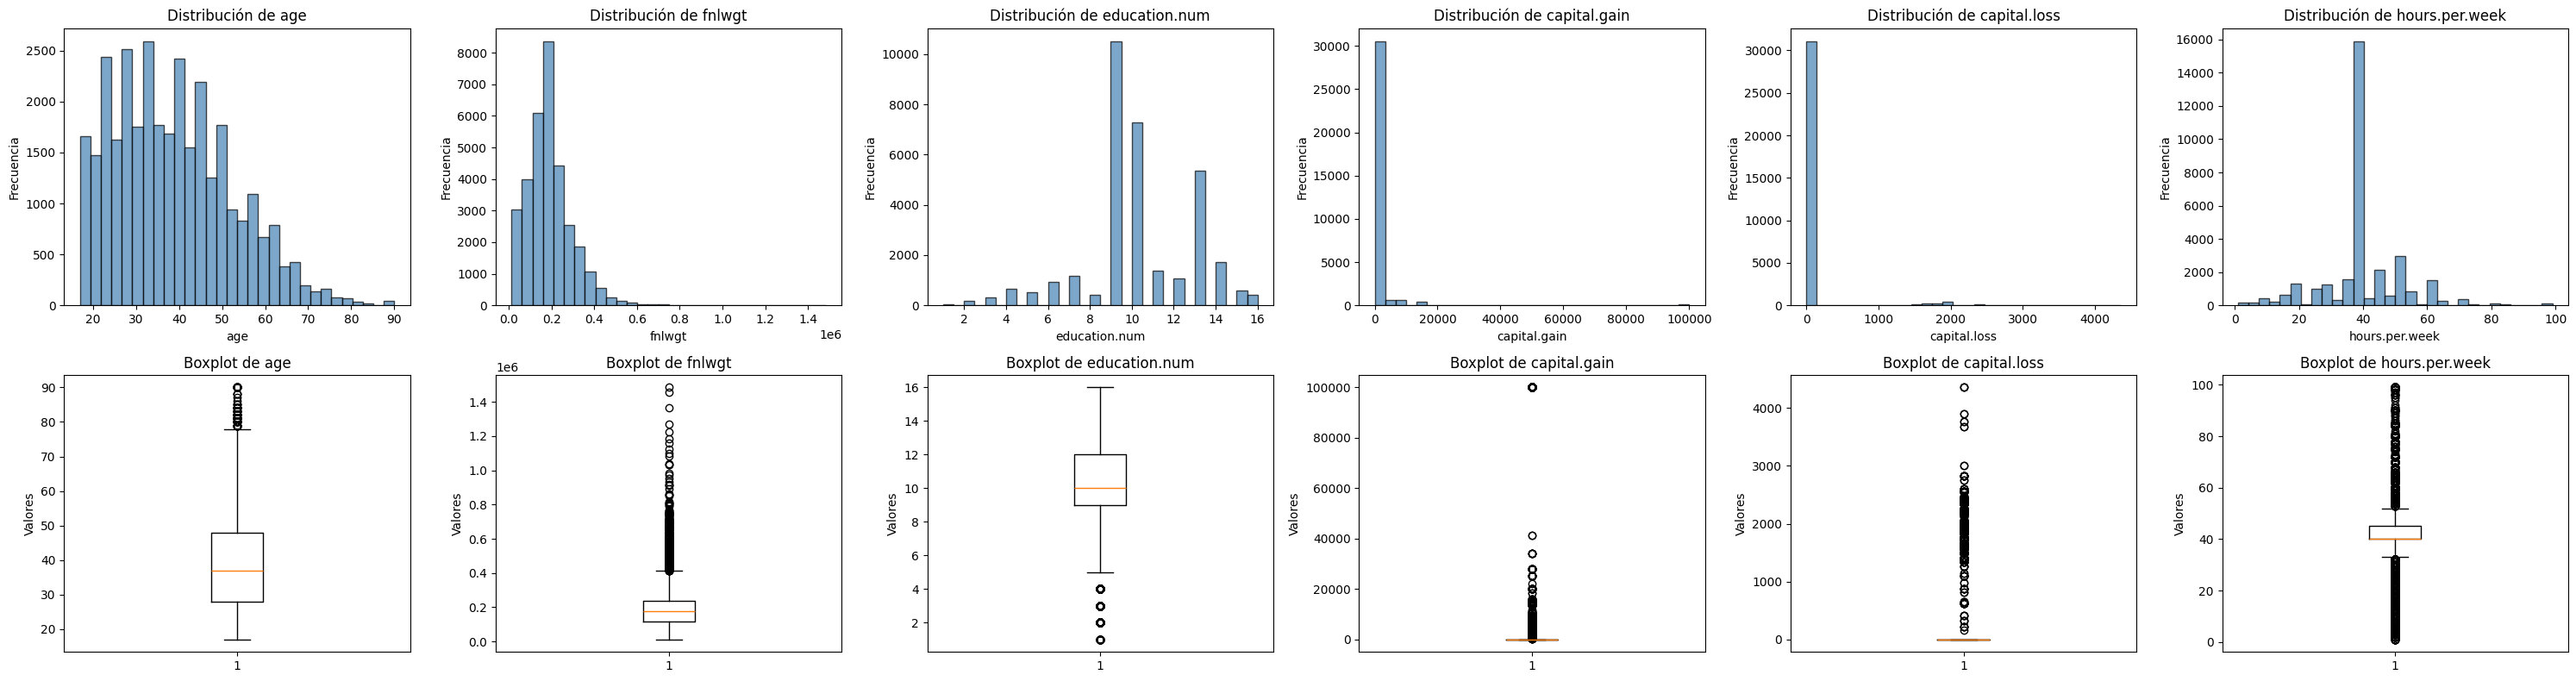


----------------------------------------
ANÁLISIS DETALLADO - VARIABLES CATEGÓRICAS
----------------------------------------

workclass:
  - Valores únicos: 9
  - Valor más frecuente: 'Private' (22696 ocurrencias)
  - Top 5 valores:
      'Private': 22696 (69.7%)
      'Self-emp-not-inc': 2541 (7.8%)
      'Local-gov': 2093 (6.4%)
      '?': 1836 (5.6%)
      'State-gov': 1298 (4.0%)

education:
  - Valores únicos: 16
  - Valor más frecuente: 'HS-grad' (10501 ocurrencias)
  - Top 5 valores:
      'HS-grad': 10501 (32.3%)
      'Some-college': 7291 (22.4%)
      'Bachelors': 5355 (16.4%)
      'Masters': 1723 (5.3%)
      'Assoc-voc': 1382 (4.2%)

marital.status:
  - Valores únicos: 7
  - Valor más frecuente: 'Married-civ-spouse' (14976 ocurrencias)
  - Top 5 valores:
      'Married-civ-spouse': 14976 (46.0%)
      'Never-married': 10683 (32.8%)
      'Divorced': 4443 (13.6%)
      'Separated': 1025 (3.1%)
      'Widowed': 993 (3.0%)

RESUMEN EJECUTIVO
• Dataset: 32561 filas × 15 colum

In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# ===== PARTE 1: CARGA Y EXPLORACIÓN INICIAL DEL DATASET =====

# Cargar el dataset
dataset_path = "/home/jujgomezru/.cache/kagglehub/datasets/mosapabdelghany/adult-income-prediction-dataset/versions/1"

# Ver qué archivos hay disponibles y cargar el CSV
print("Archivos en el directorio:")
for file in os.listdir(dataset_path):
    print(f"- {file}")

# Cargar el dataset (buscar archivo CSV)
csv_files = [f for f in os.listdir(dataset_path) if f.endswith('.csv')]
if csv_files:
    file_path = os.path.join(dataset_path, csv_files[0])
    df = pd.read_csv(file_path)
    print(f"\nDataset cargado desde: {file_path}")
else:
    print("No se encontraron archivos CSV.")
    # En caso de no encontrar CSV, podríamos agregar manejo de otros formatos aquí

print("\n" + "="*50)
print("INFORMACIÓN GENERAL DEL DATASET")
print("="*50)

print(f"Dimensiones: {df.shape} (filas, columnas)")
print(f"\nPrimeras 5 filas:")
print(df.head())

print(f"\nInformación de columnas y tipos de datos:")
print(df.info())

print(f"\nEstadísticas descriptivas de variables numéricas:")
print(df.describe())

print(f"\nValores nulos por columna:")
print(df.isnull().sum())

# ===== PARTE 2: ANÁLISIS DE LA VARIABLE OBJETIVO Y CARACTERÍSTICAS =====

# Variable objetivo conocida
target_column = 'income'

# Separar características (X) y objetivo (y)
X = df.drop(columns=[target_column])
y = df[target_column]

print("\n" + "="*50)
print("ANÁLISIS DE LA VARIABLE OBJETIVO")
print("="*50)

print(f"Variable objetivo: '{target_column}'")
print(f"\nDistribución absoluta:")
print(y.value_counts())

print(f"\nDistribución porcentual:")
print(y.value_counts(normalize=True).round(3))

# Visualizar la distribución de la variable objetivo
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
y.value_counts().plot(kind='bar', color=['skyblue', 'lightcoral'])
plt.title('Distribución de Income')
plt.xlabel('Categoría de Income')
plt.ylabel('Frecuencia')

plt.subplot(1, 2, 2)
y.value_counts().plot(kind='pie', autopct='%1.1f%%', colors=['lightgreen', 'orange'])
plt.title('Proporción de Income')
plt.ylabel('')

plt.tight_layout()
plt.show()

print("\n" + "="*50)
print("ANÁLISIS DE CARACTERÍSTICAS")
print("="*50)

print(f"Total de características: {X.shape[1]}")
print(f"Total de instancias: {X.shape[0]}")

# Identificar tipos de características
numeric_features = X.select_dtypes(include=[np.number]).columns.tolist()
categorical_features = X.select_dtypes(include=['object']).columns.tolist()

print(f"\nCaracterísticas numéricas ({len(numeric_features)}):")
for i, feature in enumerate(numeric_features, 1):
    print(f"  {i}. {feature} ({X[feature].dtype})")

print(f"\nCaracterísticas categóricas ({len(categorical_features)}):")
for i, feature in enumerate(categorical_features, 1):
    unique_vals = X[feature].nunique()
    print(f"  {i}. {feature} ({unique_vals} valores únicos)")

# Análisis de características numéricas
if numeric_features:
    print(f"\n" + "-"*40)
    print("ESTADÍSTICAS DETALLADAS - VARIABLES NUMÉRICAS")
    print("-"*40)
    
    # Crear subplots para visualizaciones
    n_numeric = len(numeric_features)
    fig, axes = plt.subplots(2, n_numeric, figsize=(5*n_numeric, 8))
    
    if n_numeric == 1:
        axes = axes.reshape(2, 1)
    
    for i, feature in enumerate(numeric_features):
        # Histograma
        axes[0, i].hist(X[feature], bins=30, alpha=0.7, color='steelblue', edgecolor='black')
        axes[0, i].set_title(f'Distribución de {feature}')
        axes[0, i].set_xlabel(feature)
        axes[0, i].set_ylabel('Frecuencia')
        
        # Boxplot
        axes[1, i].boxplot(X[feature].dropna())
        axes[1, i].set_title(f'Boxplot de {feature}')
        axes[1, i].set_ylabel('Valores')
    
    plt.tight_layout()
    plt.show()

# Análisis de características categóricas
if categorical_features:
    print(f"\n" + "-"*40)
    print("ANÁLISIS DETALLADO - VARIABLES CATEGÓRICAS")
    print("-"*40)
    
    # Mostrar información de las 3 primeras características categóricas para no saturar
    for feature in categorical_features[:3]:
        print(f"\n{feature}:")
        print(f"  - Valores únicos: {X[feature].nunique()}")
        print(f"  - Valor más frecuente: '{X[feature].mode().iloc[0]}' ({X[feature].value_counts().iloc[0]} ocurrencias)")
        print(f"  - Top 5 valores:")
        for valor, count in X[feature].value_counts().head().items():
            print(f"      '{valor}': {count} ({count/len(X)*100:.1f}%)")

# ===== RESUMEN FINAL =====
print("\n" + "="*50)
print("RESUMEN EJECUTIVO")
print("="*50)
print(f"• Dataset: {df.shape[0]} filas × {df.shape[1]} columnas")
print(f"• Variable objetivo: '{target_column}'")
print(f"• Clases: {dict(y.value_counts())}")
print(f"• Características numéricas: {len(numeric_features)}")
print(f"• Características categóricas: {len(categorical_features)}")
print(f"• Valores nulos totales: {df.isnull().sum().sum()}")

A continuación, realizamos un análisis exploratorio sencillo del dataset, para poder entender sus dimensiones y componentes. Podemos observar que tiene 32561 observaciones, y se compone de 15 features. Los features de la tabla son: Edad (numérico), Tipo de trabajo (factor), Fnlwgt (que significa peso final, numérico), nivel educativo (factor), número educativo (numérico, medida cuantitativa de logros académicos), ganancias reportadas (numérico), pérdidas reportadas (numérico), estado civil (factor), ocupación (factor), relación con el núcleo familiar (factor), raza (factor), sexo (factor), horas laborales semanales (numérico), país de origen (factor), ingresos (numérico). El feature "income" es el feature objetivo, es decir, la variable que vamos a intentar predecir, usando los otros features del dataset. También se incluye una exploración de los features numéricos, con promedio, mediana, desviación estándar y rangos intercuartílicos, así como las categorías de los features que son factores, y la distribución de los datos numéricos.

In [6]:
# Preprocesamiento de características numéricas
if numeric_features:
    scaler = StandardScaler()
    X_numeric = scaler.fit_transform(X[numeric_features])
else:
    X_numeric = np.array([]).reshape(len(X), 0)

# Preprocesamiento de características categóricas
label_encoders = {}
X_categorical_encoded = []

for col in categorical_features:
    le = LabelEncoder()
    encoded_col = le.fit_transform(X[col].astype(str))
    X_categorical_encoded.append(encoded_col)
    label_encoders[col] = le

if X_categorical_encoded:
    X_categorical = np.column_stack(X_categorical_encoded)
else:
    X_categorical = np.array([]).reshape(len(X), 0)

# Combinar características numéricas y categóricas
if X_numeric.size > 0 and X_categorical.size > 0:
    X_processed = np.column_stack([X_numeric, X_categorical])
elif X_numeric.size > 0:
    X_processed = X_numeric
else:
    X_processed = X_categorical

# Codificar la variable objetivo
label_encoder_y = LabelEncoder()
y_encoded = label_encoder_y.fit_transform(y)

print(f"Forma de X procesado: {X_processed.shape}")
print(f"Forma de y: {y_encoded.shape}")
print(f"Clases objetivo: {label_encoder_y.classes_}")

Forma de X procesado: (32561, 14)
Forma de y: (32561,)
Clases objetivo: ['<=50K' '>50K']


Una vez analizado el dataset original, comenzamos realizando un pre-procesamiento de los datos. El objetivo de esta etapa, es adaptar los datos originales, para que sean posibles de aplicar para los métodos de las librerías de Inteligencia Artificial aplicadas en este ejercicio. Lo primero que se busca hacer es normalizar los datos numéricos. Es decir, asegurarse que todas las variables cuantitativas tengan una media de 0, y una desviación estándar de 1. El objetivo de esta normalización es eliminar el peso de las escalas de los valores originales, y eliminar el factor de confusión dado por los promedios y varianzas de los datos originales, y poder compararlos entre ellos para el mismo modelo. Para los valores cualitativos, se deben transformar a una representación numérica. En este caso, se reemplaza cada texto posible por un número, que, si bien no representa el "valor" cuantitativo de la etiqueta, permite visualizar el contenido de esas variables en una matriz numérica, que es el formato de entrada para nuestro modelo. Se usa la clase LabelEncoder para el preprocesamiento de las variables cualitativas. La clase objetivo también es transformada a 0 y 1, que representan el valor objetivo de nuestra matriz.

In [7]:
# Dividir en entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X_processed, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

print(f"Entrenamiento: {X_train.shape}, {y_train.shape}")
print(f"Prueba: {X_test.shape}, {y_test.shape}")

# Diseñar la arquitectura de la red neuronal
model = keras.Sequential([
    layers.Dense(128, activation='relu', input_shape=(X_train.shape[1],)),
    layers.Dropout(0.3),
    layers.Dense(64, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(32, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(1, activation='sigmoid')  # Para clasificación binaria
])

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

print("Arquitectura de la red neuronal:")
model.summary()

Entrenamiento: (26048, 14), (26048,)
Prueba: (6513, 14), (6513,)


/home/jujgomezru/.local/lib/python3.13/site-packages/keras/src/layers/core/dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
2025-09-23 21:16:27.218155: E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Arquitectura de la red neuronal:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 12,289 (48.00 KB)

 Trainable params: 12,289 (48.00 KB)

 Non-trainable params: 0 (0.00 B)

Una vez adaptados los datos, se define y construye el modelo de redes neuronales. Primero se define un modelo de bootstrapping para el entrenamiento y validación del modelo. En este caso, se define que siempre se use un grupo aleatorio del 20% de datos como datos de validación. El parámetro stratify del método train_test_split, se usa para asegurarse que cada boot-strap tenga automáticamente la misma proporción de datos de income alto e income bajo, para que todas las muestras tomadas sean representativas de la población original. 
Una vez definido el bootstrap, se construye la red neuronal. Esta red neuronal consiste de tres capas, de 128, 64 y 32 neuronas respectivamente. La tercera capa entrega los resultados a una neurona final, que realiza la predicción oficial de income con la observación tratada. Se usa la función relu para las capas ocultas, y la función sigmoide para el resultado final. Se usa el optimizador predefinido Adam para definir el aprendizaje de las neuronas en cada iteración.

Epoch 1/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 10s 5ms/step - accuracy: 0.7569 - loss: 0.5216 - val_accuracy: 0.8144 - val_loss: 0.4174
Epoch 2/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8106 - loss: 0.4102 - val_accuracy: 0.8232 - val_loss: 0.3864
Epoch 3/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8237 - loss: 0.3788 - val_accuracy: 0.8305 - val_loss: 0.3610
Epoch 4/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8343 - loss: 0.3609 - val_accuracy: 0.8355 - val_loss: 0.3469
Epoch 5/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8397 - loss: 0.3510 - val_accuracy: 0.8359 - val_loss: 0.3439
Epoch 6/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8405 - loss: 0.3447 - val_accuracy: 0.8411 - val_loss: 0.3387
Epoch 7/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8409 - loss: 0.3415 - val_accuracy: 0.8392 - val_loss: 0.3395
Epoch 8/50
652/652 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8427 - loss: 0.3397 - val_accuracy: 0

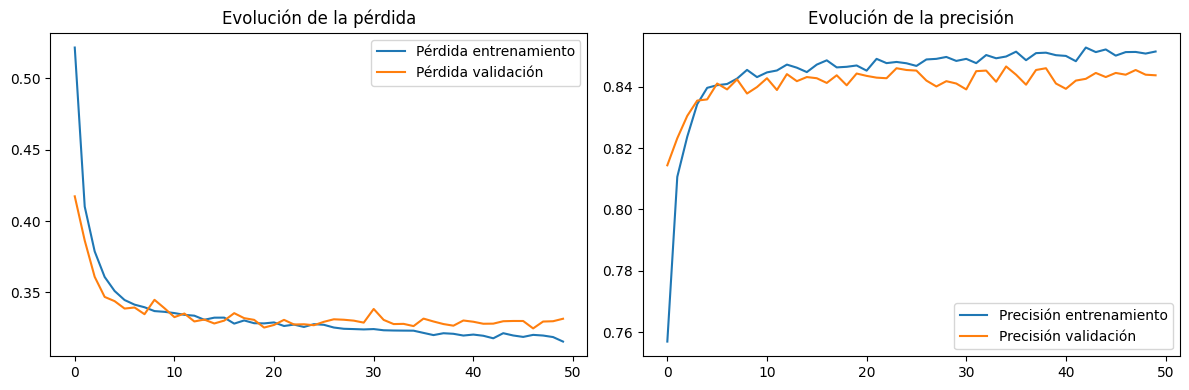

In [15]:
# Entrenar el modelo
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

# Evaluar el modelo
test_loss, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"\nPrecisión en prueba: {test_accuracy:.4f}")

# Graficar la evolución del entrenamiento
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Pérdida entrenamiento')
plt.plot(history.history['val_loss'], label='Pérdida validación')
plt.title('Evolución de la pérdida')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Precisión entrenamiento')
plt.plot(history.history['val_accuracy'], label='Precisión validación')
plt.title('Evolución de la precisión')
plt.legend()

plt.tight_layout()
plt.show()

Ahora que hemos construido el modelo, procedemos a entrenarlo. En nuestro proceso de entrenamiento definimos 50 épocas (equivalentes a las generaciones de los algoritmos genéticos) y 32 muestras por cada época (muestras de entrenamiento aleatorias definidas en el bootstrap anterior). Observamos como a medida que va avanzando el entrenamiento, logramos disminuir la pérdida de la red, es decir, las predicciones incorrectas del modelo. Se usó dropout en el diseño de la red neuronal para evitar correr con un riesgo de sobre-entrenamiento. Al final aparecen gráficas de evolución de la pérdida y precisión, mostrando como al inicio mejora el modelo, y luego se estabiliza cuando se consiguen buenos resultados, y las variaciones de los parámetros no generan ganancias significativas.

Pesos primera capa: (14, 128)
Biases primera capa: (128,)


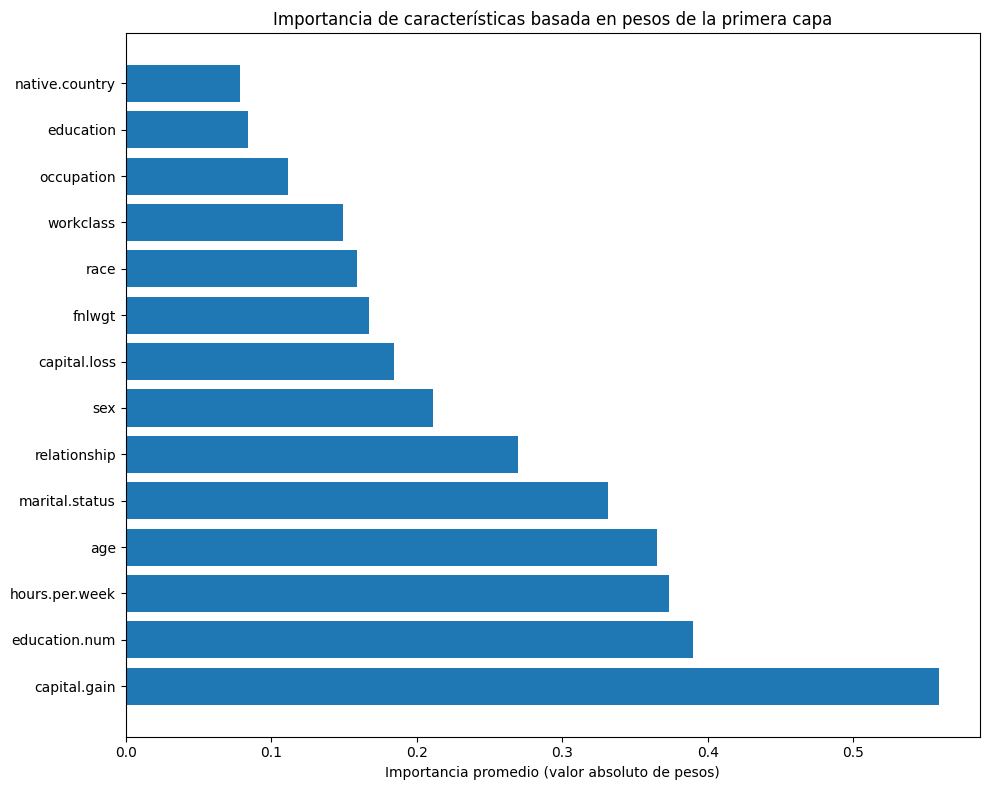


=== EJEMPLOS DE PESOS APRENDIDOS ===
Pesos para las primeras 5 características en las primeras 10 neuronas:
[[-0.13080123 -0.25341883 -0.21927209 -0.11431616 -0.06293061  0.01886617
  -0.43412077 -0.64283186 -0.0366631   0.04128291]
 [-0.09303761 -0.16412957  0.13503742  0.04957094  0.37609157  0.11642924
   0.27036074  0.02406221  0.01894069 -0.24762109]
 [-0.32328063  0.18854097  0.85222614  0.6957249   0.08743789 -0.12799823
  -0.36669353  0.38199428 -0.03833368  0.34384757]
 [-0.7366952   0.17259991  0.36835825  0.95783174  0.47368273 -1.1404023
  -0.43280405  0.08540424  0.18298501  0.7431485 ]
 [ 0.04726207  0.10848731 -0.01578271  0.14717881 -0.07164072  0.13711907
  -0.07287806 -0.33252674  0.00123014 -0.5211915 ]]


In [16]:
# Obtener los pesos de la primera capa
weights_layer1 = model.layers[0].get_weights()[0]
biases_layer1 = model.layers[0].get_weights()[1]

print(f"Pesos primera capa: {weights_layer1.shape}")
print(f"Biases primera capa: {biases_layer1.shape}")

# Analizar la importancia de las características
feature_importance = np.mean(np.abs(weights_layer1), axis=1)

# Crear nombres de características combinadas
all_feature_names = numeric_features + categorical_features

plt.figure(figsize=(10, 8))
indices = np.argsort(feature_importance)[::-1]
plt.barh(range(len(indices)), feature_importance[indices])
plt.yticks(range(len(indices)), [all_feature_names[i] for i in indices])
plt.title('Importancia de características basada en pesos de la primera capa')
plt.xlabel('Importancia promedio (valor absoluto de pesos)')
plt.tight_layout()
plt.show()

# Mostrar algunos ejemplos de pesos específicos
print("\n=== EJEMPLOS DE PESOS APRENDIDOS ===")
print("Pesos para las primeras 5 características en las primeras 10 neuronas:")
print(weights_layer1[:5, :10])

Una veez entrenado el modelo, buscamos analizar los resultados. Primero, obtenemos todos los pesos de las neuronas, para obtener los coeficientes que definen nuestra mejor red neuronal para la predicción, y luego, se extraen estos componentes, para determinar cuales features, son los más relevantes para definir estos pesos. Se incluye una gráfica que muestra los features con mayor relevancia para la predicción del rótulo objetivo. En este caso, los ingresos totales son la caracteristica que tuvo más impacto en la capacidad predictiva de la red neuronal.

204/204 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


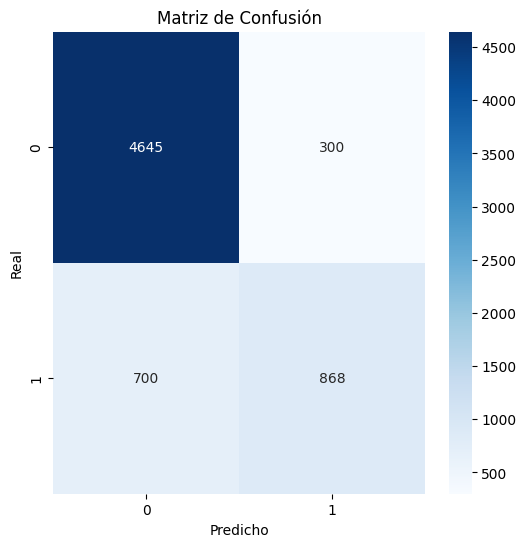


=== REPORTE DE CLASIFICACIÓN ===
              precision    recall  f1-score   support

       <=50K       0.87      0.94      0.90      4945
        >50K       0.74      0.55      0.63      1568

    accuracy                           0.85      6513
   macro avg       0.81      0.75      0.77      6513
weighted avg       0.84      0.85      0.84      6513


=== EJEMPLOS DE PREDICCIONES ===
Ejemplo 1:
  Real: <=50K (0)
  Predicho: <=50K (0)
  Probabilidad: 0.0016
  Correcto: True

Ejemplo 2:
  Real: <=50K (0)
  Predicho: <=50K (0)
  Probabilidad: 0.0090
  Correcto: True

Ejemplo 3:
  Real: >50K (1)
  Predicho: <=50K (0)
  Probabilidad: 0.1140
  Correcto: False

Ejemplo 4:
  Real: >50K (1)
  Predicho: <=50K (0)
  Probabilidad: 0.2365
  Correcto: False

Ejemplo 5:
  Real: >50K (1)
  Predicho: >50K (1)
  Probabilidad: 0.7254
  Correcto: True

Ejemplo 6:
  Real: <=50K (0)
  Predicho: <=50K (0)
  Probabilidad: 0.2538
  Correcto: True

Ejemplo 7:
  Real: <=50K (0)
  Predicho: <=50K (0)
  Pr

In [17]:
# Hacer predicciones
y_pred_proba = model.predict(X_test)
y_pred = (y_pred_proba > 0.5).astype(int)

# Matriz de confusión
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title('Matriz de Confusión')
plt.ylabel('Real')
plt.xlabel('Predicho')
plt.show()

# Reporte de clasificación
print("\n=== REPORTE DE CLASIFICACIÓN ===")
print(classification_report(y_test, y_pred, target_names=label_encoder_y.classes_))

# Ejemplos específicos de predicciones
print("\n=== EJEMPLOS DE PREDICCIONES ===")
np.random.seed(42)
sample_indices = np.random.choice(len(X_test), 10, replace=False)

for i, idx in enumerate(sample_indices):
    actual = y_test[idx]
    predicted = y_pred[idx][0]
    probability = y_pred_proba[idx][0]
    
    print(f"Ejemplo {i+1}:")
    print(f"  Real: {label_encoder_y.classes_[actual]} ({actual})")
    print(f"  Predicho: {label_encoder_y.classes_[predicted]} ({predicted})")
    print(f"  Probabilidad: {probability:.4f}")
    print(f"  Correcto: {actual == predicted}")
    print()

A continuación realizamos predicciones con la red neuronal resultante de nuestro entrenamiento, para visualizar la capacidad pedictiva de la red neuronal. Usamos una matriz de confusión para visualizar el porcentaje de aciertos, y potencialmente determinar si uno de los tipos de error del modelo es más prevalente que otros. En este ejemplo, observamos que los tres tipos de errores están relativamente distribuidos, y se consigue una habilidad predictiva del 84%. Esto es relativamente alto, si se tiene en cuenta que, en general, las características demográficas o el tipo de trabajo de un individuo no son por si solos grandes predictores del salario de una persona.

In [18]:
def predecir_ingreso(nuevos_datos, modelo, scaler, label_encoders, numeric_features, categorical_features):
    """
    Función para predecir nuevos casos
    """
    # Preprocesar los nuevos datos
    processed_data = []
    
    # Procesar características numéricas
    if numeric_features:
        numeric_data = scaler.transform(nuevos_datos[numeric_features])
        processed_data.append(numeric_data)
    
    # Procesar características categóricas
    for col in categorical_features:
        if col in nuevos_datos.columns:
            # Para valores nuevos no vistos, usar 'unknown'
            known_categories = set(label_encoders[col].classes_)
            nuevos_datos[col] = nuevos_datos[col].apply(
                lambda x: x if x in known_categories else 'unknown'
            )
            encoded_col = label_encoders[col].transform(nuevos_datos[col])
            processed_data.append(encoded_col.reshape(-1, 1))
    
    # Combinar todas las características
    X_new = np.column_stack(processed_data)
    
    # Hacer predicción
    probabilidades = modelo.predict(X_new)
    predicciones = (probabilidades > 0.5).astype(int)
    
    # Convertir a etiquetas originales
    etiquetas_predichas = label_encoder_y.inverse_transform(predicciones.flatten())
    
    resultados = pd.DataFrame({
        'Probabilidad': probabilidades.flatten(),
        'Prediccion': etiquetas_predichas
    })
    
    return resultados

Una vez se obtiene el resultado final de la red neuronal, se construye la función equivalente, que, reciba una matriz equivalente a la matriz construida con el preprocesamiento de datos (es decir, una observación válida para el dataset, procesada para poder ser evaluadapor las neuronas). Esta función por tanto, ofrece las predicciones para un hipotético nuevo grupo de datos del mismo fenómeno. A continuación, simulamos un nuevo grupo de datos, con etiquetas preestablecidas, y evaluamos la capacidad predictiva del modelo con este nuevo grupo de datos, diferentes a las secciones de validación del entrenamiento original.

In [19]:
# Verificar las características y sus valores únicos
print("=== ESTRUCTURA DEL DATASET REAL ===")
print("Características numéricas:", numeric_features)
print("Características categóricas:", categorical_features)

print("\nValores únicos por característica categórica:")
for feature in categorical_features:
    if feature in df.columns:
        unique_vals = df[feature].unique()
        print(f"{feature}: {list(unique_vals)}")

print("\nRangos de características numéricas:")
for feature in numeric_features:
    if feature in df.columns:
        min_val = df[feature].min()
        max_val = df[feature].max()
        print(f"{feature}: [{min_val}, {max_val}]")

# Ver la distribución de la variable objetivo
print(f"\nDistribución de '{target_column}':")
print(df[target_column].value_counts())

=== ESTRUCTURA DEL DATASET REAL ===
Características numéricas: ['age', 'fnlwgt', 'education.num', 'capital.gain', 'capital.loss', 'hours.per.week']
Características categóricas: ['workclass', 'education', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']

Valores únicos por característica categórica:
workclass: ['?', 'Private', 'State-gov', 'Federal-gov', 'Self-emp-not-inc', 'Self-emp-inc', 'Local-gov', 'Without-pay', 'Never-worked']
education: ['HS-grad', 'Some-college', '7th-8th', '10th', 'Doctorate', 'Prof-school', 'Bachelors', 'Masters', '11th', 'Assoc-acdm', 'Assoc-voc', '1st-4th', '5th-6th', '12th', '9th', 'Preschool']
marital.status: ['Widowed', 'Divorced', 'Separated', 'Never-married', 'Married-civ-spouse', 'Married-spouse-absent', 'Married-AF-spouse']
occupation: ['?', 'Exec-managerial', 'Machine-op-inspct', 'Prof-specialty', 'Other-service', 'Adm-clerical', 'Craft-repair', 'Transport-moving', 'Handlers-cleaners', 'Sales', 'Farming-fishing', 'Tech

In [20]:
# Crear datos de ejemplo basados en la estructura real
def crear_datos_ejemplo(n_ejemplos=10):
    """
    Crea datos de ejemplo sintéticos que siguen la estructura del dataset real
    """
    np.random.seed(42)
    
    datos_ejemplo = []
    
    for i in range(n_ejemplos):
        ejemplo = {}
        
        # Generar valores para características numéricas (basado en los rangos reales)
        for feature in numeric_features:
            if feature in df.columns:
                min_val = df[feature].min()
                max_val = df[feature].max()
                # Generar valor dentro del rango real
                ejemplo[feature] = np.random.uniform(min_val, max_val)
        
        # Generar valores para características categóricas (basado en valores reales)
        for feature in categorical_features:
            if feature in df.columns:
                unique_vals = df[feature].dropna().unique()
                # Escoger un valor aleatorio de los valores reales
                ejemplo[feature] = np.random.choice(unique_vals)
        
        datos_ejemplo.append(ejemplo)
    
    return pd.DataFrame(datos_ejemplo)

# Crear 10 ejemplos
datos_ejemplo = crear_datos_ejemplo(10)
print("=== DATOS DE EJEMPLO CREADOS ===")
print(datos_ejemplo)

=== DATOS DE EJEMPLO CREADOS ===
         age        fnlwgt  education.num  capital.gain  capital.loss  \
0  44.341429  1.412136e+06      11.979909  59865.249761    679.617198   
1  77.768313  3.249374e+05       3.727375  18340.267581   1325.279210   
2  33.992308  1.456957e+05      10.275790  38245.816665   4282.953739   
3  87.491138  1.202585e+06       5.569207   9767.113729   2980.519063   
4  72.141383  6.382930e+05       4.119125  56769.465082    136.400702   
5  78.650971  1.112654e+06       9.095382  58674.529815   4204.652118   
6  73.373868  3.048779e+05       1.082832  81545.327384   3079.070590   
7  79.052816  6.740652e+05       2.431152  37081.454402   2913.472497   
8  78.970709  1.074974e+06       4.539774  25606.576208    176.128716   
9  83.252353  3.793479e+05       7.155744  75554.358303    996.644809   

   hours.per.week         workclass    education         marital.status  \
0       16.287463       Without-pay    Doctorate          Never-married   
1       52.42

In [21]:
def predecir_ingreso_mejorado(nuevos_datos, modelo, scaler, label_encoders, numeric_features, categorical_features, label_encoder_y):
    """
    Función mejorada para predecir nuevos casos con manejo robusto de errores
    """
    try:
        # Hacer una copia para no modificar los datos originales
        datos_procesar = nuevos_datos.copy()
        
        # Verificar que todas las características necesarias estén presentes
        características_requeridas = set(numeric_features + categorical_features)
        características_disponibles = set(datos_procesar.columns)
        
        características_faltantes = características_requeridas - características_disponibles
        if características_faltantes:
            print(f"Advertencia: Faltan características: {características_faltantes}")
            # Rellenar características faltantes con valores por defecto
            for feature in características_faltantes:
                if feature in numeric_features:
                    # Usar la mediana de los datos originales
                    if feature in df.columns:
                        datos_procesar[feature] = df[feature].median()
                    else:
                        datos_procesar[feature] = 0
                else:
                    # Usar el valor más frecuente
                    if feature in df.columns:
                        moda_val = df[feature].mode()[0] if not df[feature].mode().empty else 'unknown'
                        datos_procesar[feature] = moda_val
                    else:
                        datos_procesar[feature] = 'unknown'
        
        # Preprocesar características numéricas
        processed_data = []
        
        if numeric_features:
            # Asegurar que las características numéricas sean numéricas
            for feature in numeric_features:
                datos_procesar[feature] = pd.to_numeric(datos_procesar[feature], errors='coerce')
            
            # Rellenar NaN con la mediana
            for feature in numeric_features:
                if datos_procesar[feature].isnull().any():
                    median_val = df[feature].median() if feature in df.columns else 0
                    datos_procesar[feature].fillna(median_val, inplace=True)
            
            numeric_data = scaler.transform(datos_procesar[numeric_features])
            processed_data.append(numeric_data)
        
        # Preprocesar características categóricas
        for feature in categorical_features:
            if feature in datos_procesar.columns:
                # Convertir a string y manejar valores nuevos
                datos_procesar[feature] = datos_procesar[feature].astype(str)
                
                # Para valores nuevos no vistos, usar 'unknown' o el valor más frecuente
                if feature in label_encoders:
                    known_categories = set(label_encoders[feature].classes_)
                    datos_procesar[feature] = datos_procesar[feature].apply(
                        lambda x: x if x in known_categories else 'unknown'
                    )
                    
                    # Si 'unknown' no está en las categorías conocidas, usar la moda
                    if 'unknown' not in known_categories and not datos_procesar[feature].empty:
                        moda_val = df[feature].mode()[0] if not df[feature].mode().empty else 'unknown'
                        datos_procesar.loc[datos_procesar[feature] == 'unknown', feature] = moda_val
                    
                    encoded_col = label_encoders[feature].transform(datos_procesar[feature])
                    processed_data.append(encoded_col.reshape(-1, 1))
        
        # Combinar todas las características
        if processed_data:
            X_new = np.column_stack(processed_data)
        else:
            X_new = np.array([]).reshape(len(datos_procesar), 0)
        
        # Hacer predicción
        probabilidades = modelo.predict(X_new)
        predicciones = (probabilidades > 0.5).astype(int)
        
        # Convertir a etiquetas originales
        etiquetas_predichas = label_encoder_y.inverse_transform(predicciones.flatten())
        
        resultados = pd.DataFrame({
            'Probabilidad': probabilidades.flatten(),
            'Prediccion_Numerica': predicciones.flatten(),
            'Prediccion_Etiqueta': etiquetas_predichas
        })
        
        # Combinar con los datos originales para mejor visualización
        resultados_completos = pd.concat([nuevos_datos.reset_index(drop=True), 
                                        resultados.reset_index(drop=True)], axis=1)
        
        return resultados_completos
    
    except Exception as e:
        print(f"Error en la predicción: {e}")
        return None

In [22]:
# Probar la función con nuestros datos de ejemplo
print("=== PREDICCIONES CON DATOS DE EJEMPLO ===")
resultados = predecir_ingreso_mejorado(datos_ejemplo, model, scaler, label_encoders, 
                                     numeric_features, categorical_features, label_encoder_y)

if resultados is not None:
    print(resultados)
    
    # Análisis de las predicciones
    print("\n=== ANÁLISIS DE RESULTADOS ===")
    print(f"Total de predicciones: {len(resultados)}")
    print(f"Predicción 'Alto Ingreso': {sum(resultados['Prediccion_Numerica'] == 1)}")
    print(f"Predicción 'Bajo Ingreso': {sum(resultados['Prediccion_Numerica'] == 0)}")
    
    # Mostrar las predicciones con mayor confianza
    resultados['Confianza'] = np.abs(resultados['Probabilidad'] - 0.5) + 0.5
    resultados_ordenados = resultados.sort_values('Confianza', ascending=False)
    
    print("\nPredicciones con mayor confianza:")
    print(resultados_ordenados[['Probabilidad', 'Prediccion_Etiqueta', 'Confianza']].head())

=== PREDICCIONES CON DATOS DE EJEMPLO ===
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 590ms/step
         age        fnlwgt  education.num  capital.gain  capital.loss  \
0  44.341429  1.412136e+06      11.979909  59865.249761    679.617198   
1  77.768313  3.249374e+05       3.727375  18340.267581   1325.279210   
2  33.992308  1.456957e+05      10.275790  38245.816665   4282.953739   
3  87.491138  1.202585e+06       5.569207   9767.113729   2980.519063   
4  72.141383  6.382930e+05       4.119125  56769.465082    136.400702   
5  78.650971  1.112654e+06       9.095382  58674.529815   4204.652118   
6  73.373868  3.048779e+05       1.082832  81545.327384   3079.070590   
7  79.052816  6.740652e+05       2.431152  37081.454402   2913.472497   
8  78.970709  1.074974e+06       4.539774  25606.576208    176.128716   
9  83.252353  3.793479e+05       7.155744  75554.358303    996.644809   

   hours.per.week         workclass    education         marital.status  \
0       16.287463       Without-pay    D

In [23]:
# Crear casos de prueba específicos (edge cases)
def crear_casos_especificos():
    """
    Crea casos de prueba específicos para evaluar el modelo
    """
    casos_especificos = []
    
    # Caso 1: Perfil típico de alto ingreso
    casos_especificos.append({
        'age': 45,
        'education-num': 16,  # Universidad
        'hours-per-week': 50,
        'workclass': 'Private',
        'education': 'Bachelors',
        'marital-status': 'Married-civ-spouse',
        'occupation': 'Exec-managerial',
        'relationship': 'Husband',
        'race': 'White',
        'sex': 'Male',
        'native-country': 'United-States'
    })
    
    # Caso 2: Perfil típico de bajo ingreso
    casos_especificos.append({
        'age': 25,
        'education-num': 9,  # Secundaria
        'hours-per-week': 30,
        'workclass': 'Private',
        'education': 'HS-grad',
        'marital-status': 'Never-married',
        'occupation': 'Handlers-cleaners',
        'relationship': 'Own-child',
        'race': 'Black',
        'sex': 'Female',
        'native-country': 'United-States'
    })
    
    # Caso 3: Caso intermedio
    casos_especificos.append({
        'age': 35,
        'education-num': 13,  # Alguna universidad
        'hours-per-week': 40,
        'workclass': 'State-gov',
        'education': 'Some-college',
        'marital-status': 'Divorced',
        'occupation': 'Tech-support',
        'relationship': 'Unmarried',
        'race': 'Asian-Pac-Islander',
        'sex': 'Female',
        'native-country': 'India'
    })
    
    # Asegurarse de que tenemos todas las columnas necesarias
    columnas_requeridas = numeric_features + categorical_features
    casos_df = pd.DataFrame(casos_especificos)
    
    # Agregar columnas faltantes si es necesario
    for col in columnas_requeridas:
        if col not in casos_df.columns and col in df.columns:
            # Usar valor más común para esa columna
            if col in numeric_features:
                casos_df[col] = df[col].median()
            else:
                casos_df[col] = df[col].mode()[0] if not df[col].mode().empty else 'unknown'
    
    return casos_df

# Probar con casos específicos
print("=== PRUEBA CON CASOS ESPECÍFICOS ===")
casos_especificos = crear_casos_especificos()
print("Casos específicos creados:")
print(casos_especificos)

resultados_especificos = predecir_ingreso_mejorado(casos_especificos, model, scaler, label_encoders,
                                                 numeric_features, categorical_features, label_encoder_y)

if resultados_especificos is not None:
    print("\nResultados de casos específicos:")
    print(resultados_especificos)

=== PRUEBA CON CASOS ESPECÍFICOS ===
Casos específicos creados:
   age  education-num  hours-per-week  workclass     education  \
0   45             16              50    Private     Bachelors   
1   25              9              30    Private       HS-grad   
2   35             13              40  State-gov  Some-college   

       marital-status         occupation relationship                race  \
0  Married-civ-spouse    Exec-managerial      Husband               White   
1       Never-married  Handlers-cleaners    Own-child               Black   
2            Divorced       Tech-support    Unmarried  Asian-Pac-Islander   

      sex native-country    fnlwgt  education.num  capital.gain  capital.loss  \
0    Male  United-States  178356.0           10.0           0.0           0.0   
1  Female  United-States  178356.0           10.0           0.0           0.0   
2  Female          India  178356.0           10.0           0.0           0.0   

   hours.per.week      marital.status

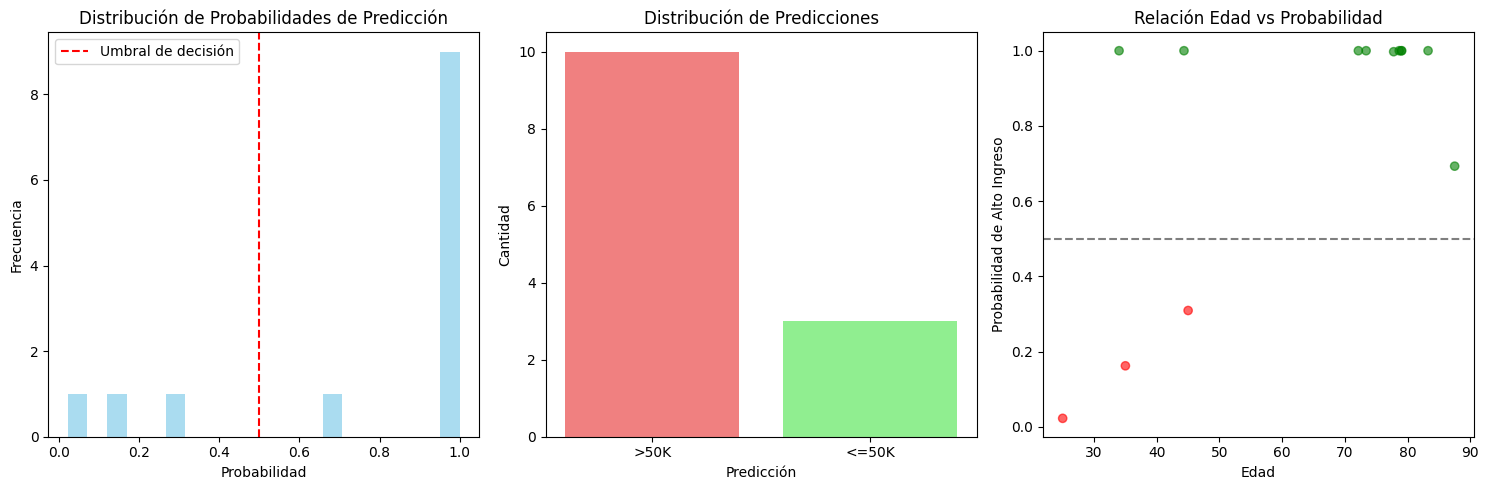


=== ANÁLISIS COMPLETO ===
Probabilidad promedio: 0.783
Probabilidad mínima: 0.023
Probabilidad máxima: 1.000
Predicciones de alto ingreso: 10
Predicciones de bajo ingreso: 3


In [24]:
# Visualizar los resultados
if resultados is not None and resultados_especificos is not None:
    # Combinar todos los resultados
    todos_resultados = pd.concat([resultados, resultados_especificos], ignore_index=True)
    
    # Crear visualizaciones
    plt.figure(figsize=(15, 5))
    
    # Gráfico 1: Distribución de probabilidades
    plt.subplot(1, 3, 1)
    plt.hist(todos_resultados['Probabilidad'], bins=20, alpha=0.7, color='skyblue')
    plt.axvline(x=0.5, color='red', linestyle='--', label='Umbral de decisión')
    plt.xlabel('Probabilidad')
    plt.ylabel('Frecuencia')
    plt.title('Distribución de Probabilidades de Predicción')
    plt.legend()
    
    # Gráfico 2: Conteo de predicciones
    plt.subplot(1, 3, 2)
    conteo_predicciones = todos_resultados['Prediccion_Etiqueta'].value_counts()
    plt.bar(conteo_predicciones.index, conteo_predicciones.values, color=['lightcoral', 'lightgreen'])
    plt.xlabel('Predicción')
    plt.ylabel('Cantidad')
    plt.title('Distribución de Predicciones')
    
    # Gráfico 3: Probabilidad vs Edad (si existe la característica age)
    if 'age' in todos_resultados.columns:
        plt.subplot(1, 3, 3)
        colors = ['red' if pred == 0 else 'green' for pred in todos_resultados['Prediccion_Numerica']]
        plt.scatter(todos_resultados['age'], todos_resultados['Probabilidad'], c=colors, alpha=0.6)
        plt.axhline(y=0.5, color='black', linestyle='--', alpha=0.5)
        plt.xlabel('Edad')
        plt.ylabel('Probabilidad de Alto Ingreso')
        plt.title('Relación Edad vs Probabilidad')
    
    plt.tight_layout()
    plt.show()
    
    # Análisis detallado
    print("\n=== ANÁLISIS COMPLETO ===")
    print(f"Probabilidad promedio: {todos_resultados['Probabilidad'].mean():.3f}")
    print(f"Probabilidad mínima: {todos_resultados['Probabilidad'].min():.3f}")
    print(f"Probabilidad máxima: {todos_resultados['Probabilidad'].max():.3f}")
    print(f"Predicciones de alto ingreso: {sum(todos_resultados['Prediccion_Numerica'] == 1)}")
    print(f"Predicciones de bajo ingreso: {sum(todos_resultados['Prediccion_Numerica'] == 0)}")

Finamente, definimos un **modelo interactivo**, que le permite al usuario crear un caso hipotético, y retorna con la predicción oficial de la red neuronal, así como con la confianza de la predicción (para identificar si es un caso muy claro, o un caso que le genere dificultades a la red para predecir claramente).

In [26]:
def probar_modelo_interactivo():
    """
    Función para probar el modelo con entradas específicas del usuario
    """
    print("=== PRUEBA INTERACTIVA DEL MODELO ===")
    print("Ingresa los valores para las características (deja vacío para usar valor por defecto):")
    
    # Recopilar entradas del usuario
    entrada_usuario = {}
    
    for feature in numeric_features + categorical_features:
        if feature in df.columns:
            valor_default = str(df[feature].mode()[0]) if feature in categorical_features else str(df[feature].median())
            entrada = input(f"{feature} (default: {valor_default}): ").strip()
            if entrada == "":
                entrada_usuario[feature] = valor_default
            else:
                entrada_usuario[feature] = entrada
    
    # Convertir a DataFrame
    datos_usuario = pd.DataFrame([entrada_usuario])
    
    # Asegurar tipos correctos
    for feature in numeric_features:
        if feature in datos_usuario.columns:
            datos_usuario[feature] = pd.to_numeric(datos_usuario[feature], errors='coerce')
    
    # Hacer predicción
    resultado = predecir_ingreso_mejorado(datos_usuario, model, scaler, label_encoders,
                                        numeric_features, categorical_features, label_encoder_y)
    
    if resultado is not None:
        print("\n=== RESULTADO ===")
        prob = resultado['Probabilidad'].iloc[0]
        prediccion = resultado['Prediccion_Etiqueta'].iloc[0]
        
        print(f"Probabilidad: {prob:.4f}")
        print(f"Predicción: {prediccion}")
        
        if prob > 0.7:
            print("Confianza: ALTA")
        elif prob > 0.6:
            print("Confianza: MEDIA")
        else:
            print("Confianza: BAJA")
    
    return resultado

# Descomenta la siguiente línea para probar interactivamente
resultado_interactivo = probar_modelo_interactivo()

=== PRUEBA INTERACTIVA DEL MODELO ===
Ingresa los valores para las características (deja vacío para usar valor por defecto):


age (default: 37.0):  25
fnlwgt (default: 178356.0):  
education.num (default: 10.0):  15
capital.gain (default: 0.0):  1
capital.loss (default: 0.0):  0
hours.per.week (default: 40.0):  45
workclass (default: Private):  Private
education (default: HS-grad):  HS-grad
marital.status (default: Married-civ-spouse):  
occupation (default: Prof-specialty):  
relationship (default: Husband):  
race (default: White):  
sex (default: Male):  
native.country (default: United-States):  


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 220ms/step

=== RESULTADO ===
Probabilidad: 0.5822
Predicción: >50K
Confianza: BAJA
